# Joint trajectory fitting for the partially observed Lorenz system

Shared Lorenz coefficients are estimated from noisy u and v sequences. The fitted law is then frozen to estimate the unmeasured coordinate w on held-out trajectories.

## Results at a glance

With noisy $u,v$ measurements, the default run selects 81 readings spanning
0.80 time units. The unmeasured $w$ has held-out endpoint RMSE of **0.07905**
with the fitted law and **0.06610** with the planted law. The fitted law
recovers all five coefficients within 0.32% of their planted values.

## Method

For independent $T$-sample trajectories indexed by $i$, fit latent states
$x_{i,k}$ and one shared coefficient vector $\theta$ by minimizing

$$
\sum_i\sum_{k=0}^{T-1}\left\|R^{-1/2}(H x_{i,k}-y_{i,k})\right\|^2
+\sum_i\sum_{k=0}^{T-2}\left\|Q^{-1/2}\left(x_{i,k+1}-\Phi_\theta(x_{i,k})\right)\right\|^2 .
$$

$H$ selects the measured coordinates and $\Phi_\theta$ is one RK4 step.
$R$ and $Q$ are diagonal matrices of squared measurement and transition-defect
scales. The simulator is deterministic apart from sensor noise. The defect
scales control the fit, and the coefficient penalty is zero.

Sparse Gauss–Newton exploits the dependence of each defect on two adjacent
states and the shared coefficients. The solver uses complex-step derivatives,
diagonal damping, and backtracking. For validation and test, each history is a
separate state-only fit. Its endpoint seeds a free rollout. The training
objective in this notebook is specific to trajectory fitting.

## Setup

Install from the repository root with `python -m pip install -e ".[notebooks]"`
and select that Python environment as the Jupyter kernel. The experiment
generates all data on CPU.

In [1]:
from functools import partial
from pathlib import Path
import sys

from IPython.display import Markdown, display
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
from scipy.integrate import solve_ivp

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
if not (root / "examples" / "trajectory_fit.py").is_file():
    raise FileNotFoundError("Run this notebook from the repository root or notebooks directory.")
sys.path.insert(0, str(root))

from examples.trajectory_fit import (
    TrajectoryFit, estimate_endpoints, initialize_observed,
    prefix_windows, rk4_step, rmse, rollout,
)

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.2,
})
colors = {"Fitted law": "#146b88", "Planted law": "#855197", "Persistence": "#666666"}
styles = {"Fitted law": "-", "Planted law": "--", "Persistence": ":"}
print(f"Python {sys.version.split()[0]}  |  NumPy {np.__version__}  |  "
      f"SciPy {scipy.__version__}  |  Matplotlib {matplotlib.__version__}")

Python 3.14.4  |  NumPy 2.5.3  |  SciPy 1.18.1  |  Matplotlib 3.11.2


## Lorenz data and candidate library

The state is $(u,v,w)$. The model fits five signed coefficients within the
prescribed family

$$
\dot{u}=a u+b v,\qquad
\dot{v}=c u+d v-u w,\qquad
\dot{w}=u v+e w .
$$

The quadratic interactions are fixed. The simulator uses the classical
coefficients $(-10,10,28,-1,-8/3)$ and a tight-tolerance DOP853 solver. Initial
conditions are uniform over $[-15,15]^2\times[10,35]$ with a 3-unit burn-in.
The first two coordinates are sampled every 0.01 time units with independent
Gaussian noise of standard deviation 0.3 per channel.

Local quadratics initialize $u$, $v$, and $\dot v$. A ridge-stabilized inversion
of the $\dot v$ equation initializes $w$ toward 24 when $u$ is small. Clipping
to $[5,50]$ applies only to the initialization. The state fit itself is
unconstrained.

In [2]:
dt = 0.01
times = dt * np.arange(241)
measurement_scale = 0.3
defect_scale = np.array([0.012, 0.020, 0.025])
state_labels = ["u", "v", "w"]
state_units = ["nondimensional"] * 3
time_unit = "time units"
sensors = 2

planted = np.array([-10.0, 10.0, 28.0, -1.0, -8.0 / 3])
terms = ["u in du/dt", "v in du/dt", "u in dv/dt", "v in dv/dt", "w in dw/dt"]
starts = np.array([
    [-6.0, 6.0, 18.0, -0.5, -1.5],
    [-8.0, 11.0, 24.0, -1.3, -2.0],
    [-13.0, 12.0, 33.0, -0.7, -3.1],
])

splits = {"train": (64, 110911), "validation": (20, 110912), "test": (48, 110913)}
origins = np.arange(80, 201, 10)
horizon = 40
start_width = 31
widths = [11, 21, 31, 51, 81]

### Simulate the reference dynamics

In [3]:
def rate(state, coefficients):
    u, v, w = np.moveaxis(state, -1, 0)
    a, b, c, d, e = coefficients
    return np.stack((a * u + b * v, c * u + d * v - u * w, u * v + e * w), axis=-1)


step = partial(rk4_step, rate, dt=dt)


def simulate(count, seed, length):
    rng = np.random.default_rng(seed)
    initial = np.column_stack((
        rng.uniform(-15, 15, count), rng.uniform(-15, 15, count), rng.uniform(10, 35, count),
    ))
    sample_times = 3.0 + times[:length]
    solution = solve_ivp(
        lambda _, state: rate(state.reshape(count, 3), planted).ravel(),
        (0.0, sample_times[-1]), initial.ravel(), t_eval=sample_times,
        method="DOP853", rtol=1e-10, atol=1e-11,
    )
    if not solution.success:
        raise RuntimeError(solution.message)
    truth = solution.y.T.reshape(length, count, 3).transpose(1, 0, 2)
    observed = truth[..., :sensors]
    return truth, observed + measurement_scale * rng.standard_normal(observed.shape)


def initialize(readings, coefficients):
    observed = initialize_observed(readings, dt)
    u = observed[..., 0, 0]
    v, dv = np.moveaxis(observed[..., 1, :], -1, 0)
    _, _, c, d, _ = coefficients
    prior_w = 24.0
    w = prior_w + u * (c * u + d * v - dv - u * prior_w) / (u**2 + 9)
    return np.stack((u, v, np.clip(w, 5, 50)), axis=-1)

## Fit and select the shared law

Fit all 64 training trajectories jointly from each of three initial coefficient
vectors. Use 141 samples per training trajectory. Score
each fitted law on 20 independent validation trajectories at the same 13
origins. Start selection uses a fixed 31-reading history.
With those coefficients frozen, score each candidate history length using the
same 40-lead RMSE against future noisy measurements.

In [4]:
training_length = 141
_, train_readings = simulate(*splits["train"], length=training_length)
_, validation_readings = simulate(*splits["validation"], length=len(times))

fit_problem = TrajectoryFit(train_readings, step, measurement_scale, defect_scale, len(terms))
future_indices = origins[:, None] + np.arange(1, horizon + 1)
validation_targets = validation_readings[:, future_indices]


def reconstruct(readings, origins, width, coefficients):
    windows = prefix_windows(readings, origins, width)
    return estimate_endpoints(windows, coefficients, step, measurement_scale, defect_scale, initialize)


def validation_rmse(width, coefficients):
    current, _ = reconstruct(validation_readings, origins, width, coefficients)
    forecast = rollout(current, coefficients, step, horizon)
    return rmse(forecast[..., :sensors], validation_targets)


candidates = []
for start in starts:
    _, coefficients, diagnostic = fit_problem.fit(initialize(train_readings, start), start)
    candidates.append((validation_rmse(start_width, coefficients), coefficients, diagnostic))

selected = min(range(len(candidates)), key=lambda index: candidates[index][0])
_, fitted, _ = candidates[selected]
fitted.setflags(write=False)
width_scores = {width: validation_rmse(width, fitted) for width in widths}
selected_width = min(width_scores, key=width_scores.get)

### Validation scores

Selection uses the unrounded scores.

In [5]:
rows = ["| Start | Updates | Maximum scaled gradient | Validation RMSE |",
        "| ---: | ---: | ---: | ---: |"]
for index, (score, _, diagnostic) in enumerate(candidates, start=1):
    updates = len(diagnostic["cost_per_sample"]) - 1
    rows.append(f"| {index} | {updates} | {diagnostic['max_scaled_gradient']:.2e} | {score:.8f} |")
display(Markdown("\n".join(rows)))

rows = ["| Readings | Validation RMSE |", "| ---: | ---: |"]
rows.extend(f"| {width} | {score:.5f} |" for width, score in width_scores.items())
display(Markdown("\n".join(rows)))
print(f"Selected start {selected + 1} and {selected_width} readings "
      f"({(selected_width - 1) * dt:.2f} {time_unit}).")

| Start | Updates | Maximum scaled gradient | Validation RMSE |
| ---: | ---: | ---: | ---: |
| 1 | 5 | 7.04e-08 | 0.36825283 |
| 2 | 5 | 8.26e-08 | 0.36825283 |
| 3 | 5 | 4.41e-08 | 0.36825283 |

| Readings | Validation RMSE |
| ---: | ---: |
| 11 | 0.88773 |
| 21 | 0.44666 |
| 31 | 0.36825 |
| 51 | 0.33646 |
| 81 | 0.33164 |

Selected start 2 and 81 readings (0.80 time units).


## Held-out state estimates and forecasts

The test split contains 48 independent trajectories. Metrics pool 13 matched
origins per trajectory from 0.80 to 2.00 time units.
State RMSE compares the fitted endpoints with noise-free states. Forecast
RMSE pools errors against noise-free $u,v$ over the next 40 leads.
The planted-law control uses the same state solver with known coefficients.
Persistence repeats the latest noisy readings.

In [6]:
test_truth, test_readings = simulate(*splits["test"], length=len(times))
current_truth = test_truth[:, origins]
future_truth = test_truth[:, future_indices, :sensors]
laws = {"Fitted law": fitted, "Planted law": planted}
current = {}
forecasts = {}
for label, coefficients in laws.items():
    current[label], _ = reconstruct(test_readings, origins, selected_width, coefficients)
    forecasts[label] = rollout(current[label], coefficients, step, horizon)[..., :sensors]
forecasts["Persistence"] = np.broadcast_to(test_readings[:, origins, None], future_truth.shape)
state_scores = {label: rmse(states, current_truth, axis=(0, 1)) for label, states in current.items()}
raw_scores = rmse(test_readings[:, origins], current_truth[..., :sensors], axis=(0, 1))
forecast_scores = {label: rmse(values, future_truth) for label, values in forecasts.items()}

### Coefficients and test scores

In [7]:
rows = ["| Term | Fitted | Planted | Absolute error |", "| --- | ---: | ---: | ---: |"]
for term, estimate, reference in zip(terms, fitted, planted):
    rows.append(f"| {term} | {estimate:.6f} | {reference:.6f} | {abs(estimate - reference):.6f} |")
display(Markdown("\n".join(rows)))

columns = " | ".join(f"{label} ({unit})" for label, unit in zip(state_labels, state_units))
rows = [f"| Endpoint estimate | {columns} |", "| --- |" + " ---: |" * len(state_labels)]
for label, scores in state_scores.items():
    rows.append(f"| {label} | " + " | ".join(f"{score:.5f}" for score in scores) + " |")
raw_cells = [f"{score:.5f}" for score in raw_scores] + ["—"] * (len(state_labels) - sensors)
rows.append("| Latest readings | " + " | ".join(raw_cells) + " |")
display(Markdown("\n".join(rows)))

rows = ["| Forecast | Pooled observed-coordinate RMSE |", "| --- | ---: |"]
rows.extend(f"| {label} | {score:.5f} |" for label, score in forecast_scores.items())
display(Markdown("\n".join(rows)))

| Term | Fitted | Planted | Absolute error |
| --- | ---: | ---: | ---: |
| u in du/dt | -10.013560 | -10.000000 | 0.013560 |
| v in du/dt | 10.009914 | 10.000000 | 0.009914 |
| u in dv/dt | 27.959515 | 28.000000 | 0.040485 |
| v in dv/dt | -1.003110 | -1.000000 | 0.003110 |
| w in dw/dt | -2.672888 | -2.666667 | 0.006222 |

| Endpoint estimate | u (nondimensional) | v (nondimensional) | w (nondimensional) |
| --- | ---: | ---: | ---: |
| Fitted law | 0.04345 | 0.07214 | 0.07905 |
| Planted law | 0.04333 | 0.07217 | 0.06610 |
| Latest readings | 0.29261 | 0.30267 | — |

| Forecast | Pooled observed-coordinate RMSE |
| --- | ---: |
| Fitted law | 0.17573 |
| Planted law | 0.17476 |
| Persistence | 8.14168 |

### Forecast error by lead

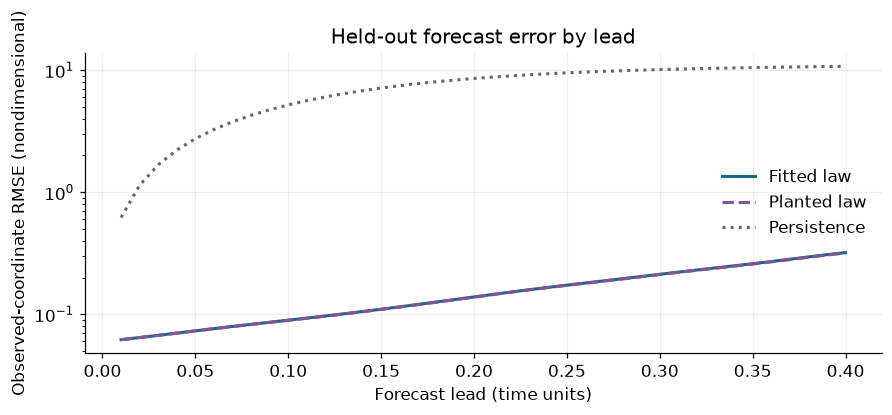

In [8]:
lead_time = dt * np.arange(1, horizon + 1)
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
for label, values in forecasts.items():
    score_by_lead = rmse(values, future_truth, axis=(0, 1, 3))
    ax.plot(lead_time, score_by_lead, styles[label], color=colors[label], label=label, linewidth=2)
ax.set(
    title="Held-out forecast error by lead",
    xlabel=f"Forecast lead ({time_unit})",
    ylabel=f"Observed-coordinate RMSE ({state_units[0]})",
    yscale="log",
)
ax.legend(frameon=False)
plt.show()

### Rolling reconstruction

The first test trajectory illustrates rolling inference. Shading marks the
samples before a full history is available.

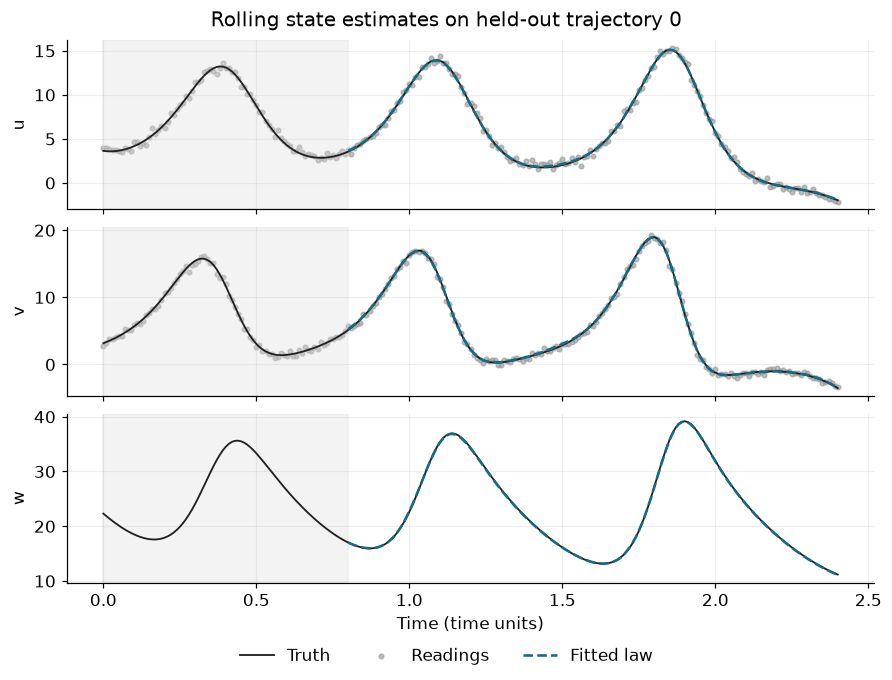

In [9]:
example_origins = np.arange(selected_width - 1, len(times))
rolling, _ = reconstruct(test_readings[:1], example_origins, selected_width, fitted)

fig, axes = plt.subplots(len(state_labels), 1, figsize=(8, 1.9 * len(state_labels) + 0.4),
                         sharex=True, layout="constrained")
for index, ax in enumerate(axes):
    ax.plot(times, test_truth[0, :, index], color="#202020", label="Truth", linewidth=1.2)
    if index < sensors:
        ax.scatter(times, test_readings[0, :, index], s=9, color="#9b9b9b", alpha=0.65, label="Readings")
    ax.plot(times[example_origins], rolling[0, :, index], "--",
            color=colors["Fitted law"], label="Fitted law", linewidth=1.7)
    ax.axvspan(times[0], times[selected_width - 1], color="#dddddd", alpha=0.35)
    ax.set_ylabel(f"{state_labels[index]}\n({state_units[index]})" if sensors == 1
                  else state_labels[index])
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="outside lower center", ncols=3)
axes[-1].set_xlabel(f"Time ({time_unit})")
fig.suptitle("Rolling state estimates on held-out trajectory 0")
plt.show()

## Numerical checks

Perturb every future reading at a sentinel origin and compare the reconstructed
endpoint and forecast bit for bit. Check the training cost traces and the
finiteness of test scores.

In [10]:
origin = origins[:1]
altered = test_readings[:1].copy()
altered[:, origin[0] + 1:] += 100.0
before, _ = reconstruct(test_readings[:1], origin, selected_width, fitted)
after, _ = reconstruct(altered, origin, selected_width, fitted)
np.testing.assert_array_equal(before, after)
np.testing.assert_array_equal(rollout(before, fitted, step, horizon), rollout(after, fitted, step, horizon))

for _, _, diagnostic in candidates:
    trace = diagnostic["cost_per_sample"]
    assert np.isfinite(trace).all() and np.all(np.diff(trace) <= 0)
    assert diagnostic["converged_fraction"] == 1.0
for scores in state_scores.values():
    assert np.isfinite(scores).all()
assert np.isfinite(list(forecast_scores.values())).all()
print("Finite scores, converged training starts, and causal endpoint and rollout verified.")

Finite scores, converged training starts, and causal endpoint and rollout verified.


## Interpretation

The fitted and planted laws yield pooled $u,v$ forecast RMSE of 0.17573 and
0.17476, respectively, over leads through 0.40 time units.

The 81-reading window is the longest in the validation grid. The result is
specific to the simulated two-sensor configuration, the supplied interaction
terms, and the evaluated short forecast horizon.